# 2-01 공시 이벤트 스터디 — 공시 뒤 주가·거래량은 어떻게 움직였나

**질문 예시:** "가온전선 무상증자 공시 나고 주가 어떻게 됐어?", "지난달 무상증자 낸 종목들 공시 후 5일 수익률 비교해줘"

CHECK 원본(`2_공시뉴스/01_공시이벤트스터디`)과 같은 6개 공시(2026년 6월)를 DeepSearch로 다시 봅니다.

| 단계 | DeepSearch 함수 |
|---|---|
| 공시 찾기(제목·시각) | `DocumentSearch(["company"],["disclosure"], "securities.name:종목 and title:키워드")` |
| 주가·거래량 | `GetStockPrices([종목들], …)` — 여러 종목을 한 번에 |
| 시장 대비 초과수익 | `GetMarketIndexes` (코스피·코스닥) |

**각색한 점:** DeepSearch에는 투자자별 수급(외국인·기관·개인)이 없어 "누가 샀나" 열은 뺐습니다.
대신 **시장(지수) 대비 초과수익**과 **공시 시각(장중/장후)**을 붙였습니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/2_disclosure_news/01_disclosure_event_study.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"

# (종목명, 제목 키워드, 검색 시작, 검색 끝) — CHECK 원본과 같은 사건
EVENTS = [
    ("가온전선", "무상증자", "2026-06-10", "2026-06-26"),
    ("카카오게임즈", "최대주주변경", "2026-06-10", "2026-06-26"),
    ("미래에셋증권", "자기주식취득", "2026-06-10", "2026-06-26"),
    ("제테마", "전환사채", "2026-06-10", "2026-06-26"),
    ("KB금융", "현금ㆍ현물배당결정", "2026-06-10", "2026-06-26"),
    ("오리온", "잠정", "2026-06-10", "2026-06-26"),
]
HORIZONS = [0, 1, 2, 5, 10]   # D0(공시 이상 첫 거래일), D+1 … 누적수익률 기준점은 D-1 종가

## 1. 공시 찾기
종목별로 기간 안에서 제목에 키워드가 든 **가장 이른 공시**를 이벤트로 잡습니다(정정공시는 제외).

In [4]:
u = universe()
name2sym = dict(zip(u["name"], u["symbol"]))
name2mkt = dict(zip(u["name"], u["market"]))

ev_rows = []
for name, kw, d1, d2 in EVENTS:
    total, docs = doc_search("company", ["disclosure"], f"securities.name:{name} and title:{kw}", d1, d2, count=20)
    docs = docs[~docs["title"].str.contains("정정")].sort_values("created_at")
    if docs.empty:
        print("공시 없음:", name, kw)
        continue
    d = docs.iloc[0]
    ev_rows.append({"종목": name, "symbol": name2sym[name], "시장": name2mkt[name],
                    "공시": d["title"], "공시시각": d["created_at"], "url": d["url"]})
events = pd.DataFrame(ev_rows)
events[["종목", "시장", "공시", "공시시각"]]

,종목,시장,공시,공시시각
0,가온전선,KOSPI,주요사항보고서(무상증자결정),2026-06-16 15:58:19
1,카카오게임즈,KOSDAQ,최대주주변경,2026-06-19 17:36:10
2,미래에셋증권,KOSPI,주요사항보고서(자기주식취득결정),2026-06-17 17:31:13
3,제테마,KOSDAQ,주요사항보고서(전환사채권발행결정),2026-06-19 16:16:02
4,KB금융,KOSPI,현금ㆍ현물배당결정(자회사의 주요경영사항),2026-06-18 16:23:38
5,오리온,KOSPI,연결재무제표기준영업(잠정)실적(공정공시),2026-06-16 09:57:38


## 2. 주가·거래량 받기 (한 번에)
공시일 앞 30거래일(거래량 평소 수준 계산용)부터 뒤 15거래일까지 받습니다.

In [5]:
p_from = (events["공시시각"].min() - pd.Timedelta(days=50)).date()
p_to = (events["공시시각"].max() + pd.Timedelta(days=25)).date()
px = stock_prices(events["symbol"].tolist(), p_from, p_to)
def market_index(d1, d2):
    """코스피·코스닥 종가. GetMarketIndexes 는 긴 기간이면 최근 약 1,300행(≈118거래일)만 주고
    앞을 잘라내므로(2026-11-25 확인) 90일씩 나눠 받는다."""
    parts, cur, end = [], pd.Timestamp(d1), pd.Timestamp(d2)
    while cur <= end:
        nxt = min(cur + pd.Timedelta(days=89), end)
        parts.append(index_prices(cur.date(), nxt.date()))
        cur = nxt + pd.Timedelta(days=1)
    i = pd.concat(parts).drop_duplicates(["date", "symbol"])
    return i[i["symbol"].isin(["KRX:KOSPI", "KRX:KOSDAQ"])].pivot_table(index="date", columns="symbol", values="close")

idx = market_index(p_from, p_to)
print(PRICE_NOTICE)
print(f"시세 {len(px):,}행, 기간 {p_from} ~ {p_to}")

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).
시세 318행, 기간 2026-04-27 ~ 2026-07-14


## 3. 이벤트 스터디
- **D0** = 공시일 이상 첫 거래일 (CHECK와 같은 정의). 15:30 이후 공시는 실제 반응이 D+1부터일 수 있어 `장후` 표시를 붙입니다.
- **누적수익률** = D-1 종가 대비. **초과수익** = 같은 기간 해당 시장 지수 수익률을 뺀 값.
- **거래량 배수** = D0~D+5 중 최대 거래량 ÷ D-20~D-1 평균 거래량.

In [6]:
def event_study(px, idx, sym, when, market, horizons=HORIZONS):
    s = px[px["symbol"] == sym].set_index("date").sort_index()
    days = s.index
    d0_pos = days.searchsorted(pd.Timestamp(when.date()))
    if d0_pos == 0 or d0_pos >= len(days):
        return None
    base = s["close"].iloc[d0_pos - 1]
    ibase = idx[f"KRX:{market}"].reindex(days).iloc[d0_pos - 1]
    out = {"D0": days[d0_pos].date()}
    for h in horizons:
        if d0_pos + h < len(days):
            r = s["close"].iloc[d0_pos + h] / base - 1
            ir = idx[f"KRX:{market}"].reindex(days).iloc[d0_pos + h] / ibase - 1
            out[f"D+{h}"] = round(r * 100, 1)
            out[f"초과 D+{h}"] = round((r - ir) * 100, 1)
    vol_base = s["volume"].iloc[max(0, d0_pos - 20):d0_pos].mean()
    win = s["volume"].iloc[d0_pos:d0_pos + 6]
    out["거래량 최대배수"] = round(win.max() / vol_base, 1)
    out["최대배수일"] = f"D+{int(win.values.argmax())}"
    return out

rows = []
for _, e in events.iterrows():
    r = event_study(px, idx, e["symbol"], e["공시시각"], e["시장"])
    if r:
        rows.append({"종목": e["종목"], "공시": e["공시"][:22], "시각": e["공시시각"].strftime("%m-%d %H:%M"),
                     "장후": e["공시시각"].hour * 100 + e["공시시각"].minute >= 1530, **r})
res = pd.DataFrame(rows)
res[["종목", "공시", "시각", "장후", "D0", "D+0", "D+1", "D+2", "D+5", "D+10", "초과 D+5", "거래량 최대배수", "최대배수일"]]

,종목,공시,시각,장후,D0,D+0,D+1,D+2,D+5,D+10,초과 D+5,거래량 최대배수,최대배수일
0,가온전선,주요사항보고서(무상증자결정),06-16 15:58,True,2026-06-16,4.2,35.3,53.0,31.5,-7.3,35.6,2.4,D+2
1,카카오게임즈,최대주주변경,06-19 17:36,True,2026-06-19,-1.1,12.7,-2.0,-22.2,-11.9,-7.3,25.0,D+1
2,미래에셋증권,주요사항보고서(자기주식취득결정),06-17 17:31,True,2026-06-17,-1.8,-1.2,-5.0,-18.6,-14.9,-15.7,1.4,D+4
3,제테마,주요사항보고서(전환사채권발행결정),06-19 16:16,True,2026-06-19,-1.7,-1.1,-4.1,-9.7,18.3,5.3,1.9,D+1
4,KB금융,현금ㆍ현물배당결정(자회사의 주요경영사항),06-18 16:23,True,2026-06-18,-0.5,-3.5,-4.3,-7.4,0.6,-8.1,1.4,D+1
5,오리온,연결재무제표기준영업(잠정)실적(공정공시),06-16 09:57,False,2026-06-16,0.1,1.0,0.1,-6.2,-1.4,-2.2,1.8,D+1


수익률 단위는 %입니다. 예: `D+5 = 31.6`은 D-1 종가 대비 5거래일 뒤 +31.6%.

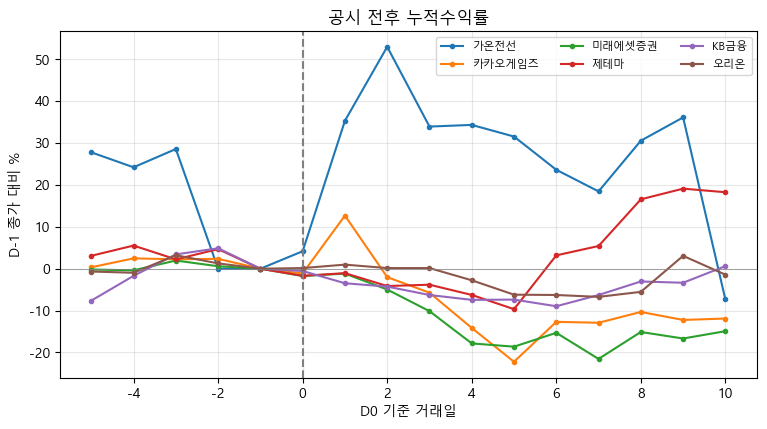

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for _, e in events.iterrows():
    s = px[px["symbol"] == e["symbol"]].set_index("date").sort_index()["close"]
    pos = s.index.searchsorted(pd.Timestamp(e["공시시각"].date()))
    path = s.iloc[max(0, pos - 5): pos + 11] / s.iloc[pos - 1] * 100 - 100
    ax.plot(range(-min(5, pos), -min(5, pos) + len(path)), path.values, marker=".", label=e["종목"])
ax.axvline(0, color="gray", ls="--"); ax.axhline(0, color="gray", lw=.5)
ax.set_xlabel("D0 기준 거래일"); ax.set_ylabel("D-1 종가 대비 %"); ax.set_title("공시 전후 누적수익률")
ax.legend(ncol=3, fontsize=8); ax.grid(alpha=.3)

## 4. 확장 — 같은 종류 공시를 한꺼번에 비교
"지난달 무상증자 낸 종목들 공시 후 수익률"처럼 **공시 종류 하나를 기간 전체로** 모아 봅니다.
회사가 직접 낸 `무상증자결정` 공시만 쓰고(권리락·추가상장 같은 거래소 후속 공시는 제외), 시세는 다시 한 번에 받습니다.

In [8]:
KIND, K_FROM, K_TO = "무상증자결정", "2026-06-01", "2026-10-31"
total, docs = doc_search("company", ["disclosure"], f"title:{KIND}", K_FROM, K_TO, count=100)
docs = docs[(docs["symbols"] != "") & ~docs["title"].str.contains("정정")]
# 공시 문서의 종목코드는 "117670"처럼 KRX: 접두어가 없다
docs["symbol"] = "KRX:" + docs["symbols"].str.split(", ").str[0]
docs = docs[docs["symbol"].isin(u["symbol"])].sort_values("created_at").drop_duplicates("symbol")
print(f"'{KIND}' 공시 {total}건 → 상장사 {len(docs)}개 종목")

b_from, b_to = (pd.Timestamp(K_FROM) - pd.Timedelta(days=45)).date(), (pd.Timestamp(K_TO) + pd.Timedelta(days=25)).date()
px2 = stock_prices(docs["symbol"].tolist(), b_from, b_to)
idx2 = market_index(b_from, b_to)
rows = []
for _, d in docs.iterrows():
    mk = u.set_index("symbol").loc[d["symbol"], "market"]
    if mk not in ("KOSPI", "KOSDAQ"):
        continue
    r = event_study(px2, idx2, d["symbol"], d["created_at"], mk, horizons=[0, 1, 5])
    if r and "D+5" in r:
        rows.append({"종목": d["stocks"].split(", ")[0], "공시일": d["created_at"].date(), **r})
bulk = pd.DataFrame(rows)
print("평균(%):", bulk[["D+0", "D+1", "D+5", "초과 D+5"]].mean().round(1).to_dict(),
      "| 중앙값 D+5:", round(bulk["D+5"].median(), 1), "| D+5 상승 종목 비율:", f"{(bulk['D+5'] > 0).mean():.0%}")
bulk.sort_values("D+5", ascending=False)[["종목", "공시일", "D0", "D+0", "D+1", "D+5", "초과 D+5", "거래량 최대배수"]]

'무상증자결정' 공시 29건 → 상장사 20개 종목


평균(%): {'D+0': 10.7, 'D+1': 15.5, 'D+5': 10.5, '초과 D+5': 14.8} | 중앙값 D+5: 11.0 | D+5 상승 종목 비율: 85%


,종목,공시일,D0,D+0,D+1,D+5,초과 D+5,거래량 최대배수
4,가온전선,2026-06-16,2026-06-16,4.2,35.3,31.5,35.6,2.4
19,알파칩스,2026-10-07,2026-10-07,30.0,26.1,30.0,47.3,6.1
14,미트박스,2026-09-02,2026-09-02,11.0,16.8,23.5,22.4,63.4
2,엠앤씨솔루션,2026-06-12,2026-06-12,24.3,22.6,18.5,1.9,5.1
1,이노스페이스,2026-06-05,2026-06-05,4.2,10.7,16.2,18.1,1.6
18,케이아이이,2026-10-06,2026-10-06,17.1,19.3,15.8,30.0,15.7
0,오에스피,2026-06-04,2026-06-04,8.8,15.8,15.6,18.5,19.9
17,MH에탄올,2026-10-01,2026-10-01,9.8,12.8,12.1,18.7,30.2
7,부스타,2026-07-07,2026-07-07,14.8,12.7,11.6,19.1,7.4
16,프로티아,2026-09-29,2026-09-29,8.3,10.4,11.3,5.2,11.4


## 결과 읽는 법과 한계
- 같은 종류 공시라도 시장 국면에 따라 반응이 다릅니다. 1건은 사례일 뿐이고, 4절처럼 여러 건을 모아 평균·중앙값을 같이 보세요.
- **수급(외국인·기관·개인)은 DeepSearch에 없습니다**(`research/data_gaps`). "누가 샀나"는 이 노트북으로 답할 수 없습니다.
- 주가는 수정주가라 무상증자 권리락이 과거 가격에 소급 반영돼 있습니다. 권리락 전후로 가격이 끊기지 않으니 수익률 계산에는 오히려 맞습니다.
- 공시 시각은 DART 접수 시각입니다. `장후`(15:30 이후) 공시는 D0 수익률에 반영되지 않았을 수 있습니다.